# SemaforoIA · 04 · Destilación de Conocimiento, Ensambles y Modelo Híbrido

En este cuaderno evaluamos sobre el **mismo conjunto de prueba (`n = 247` imágenes equilibradas)** seis estrategias de modelado a partir de nuestras dos arquitecturas entrenadas:

1. **Modelo Estudiante Destilado (`MobileNetV2`):** Entrenado mediante *Knowledge Distillation* ($T=4.0, \alpha=0.7$) a partir del Maestro.
2. **Modelo Maestro (`ResNet50`):** Arquitectura profunda de 24,56 millones de parámetros.
3. **Ensamble por Promedio (*Soft Voting* 50/50):** Promedio aritmético de las distribuciones de probabilidad de ambos modelos.
4. **Ensamble Ponderado (*Weighted Soft Voting*):** Combinación convexa $(1 - w)\,P_{\text{MobileNetV2}} + w\,P_{\text{ResNet50}}$ optimizando $w$ sobre el conjunto de validación.
5. **Modelo Híbrido (Fusión de Características + Cascada Adaptativa):**
   - *Híbrido por Fusión (Feature Stacking):* Concatenación de los vectores de características de `MobileNetV2` (`1280-d` + `256-d`) y las activaciones de `ResNet50` alimentando un clasificador MLP conjunto con `BatchNorm` y `Dropout`.
   - *Híbrido en Cascada (Routing por Confianza):* Inferencia rápida con `MobileNetV2` por defecto y consulta selectiva a `ResNet50` únicamente cuando la confianza de `MobileNetV2` cae por debajo del umbral $\tau = 0.85$.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v2, resnet50

torch.manual_seed(42)
np.random.seed(42)

RUTA_EST = Path("modelo/mobilenetv2_semaforo.pt")
RUTA_MAE = Path("modelo/resnet50_maestro.pt")
CACHE_KD = Path("modelo/cache_rasgos_kd.pt")

cache = torch.load(CACHE_KD, map_location="cpu", weights_only=True)
lm_tr, lm_va, lm_te = cache["logits_m_tr"], cache["logits_m_va"], cache["logits_m_te"]
re_tr, re_va, re_te = cache["rasgos_e_tr"], cache["rasgos_e_va"], cache["rasgos_e_te"]
y_tr, y_va, y_te = cache["etiq_tr"], cache["etiq_va"], cache["etiq_te"]

paq_e = torch.load(RUTA_EST, map_location="cpu", weights_only=True)
CLASES = paq_e["clases"]

cabeza_e = nn.Sequential(
    nn.Dropout(0.2), nn.Linear(1280, 256), nn.ReLU(inplace=True),
    nn.Dropout(0.3), nn.Linear(256, len(CLASES)),
)
sd_cabeza = {k.replace("classifier.", ""): v for k, v in paq_e["state_dict"].items() if k.startswith("classifier.")}
cabeza_e.load_state_dict(sd_cabeza)
cabeza_e.eval()

with torch.no_grad():
    le_tr, le_va, le_te = cabeza_e(re_tr), cabeza_e(re_va), cabeza_e(re_te)
    pm_va, pm_te = F.softmax(lm_va, dim=1), F.softmax(lm_te, dim=1)
    pe_va, pe_te = F.softmax(le_va, dim=1), F.softmax(le_te, dim=1)

def f1_macro(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    total = 0.0
    for c in range(len(CLASES)):
        vp = int(((y_pred == c) & (y_true == c)).sum())
        fp = int(((y_pred == c) & (y_true != c)).sum())
        fn = int(((y_pred != c) & (y_true == c)).sum())
        prec = vp / (vp + fp) if vp + fp else 0.0
        rec = vp / (vp + fn) if vp + fn else 0.0
        total += 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return total / len(CLASES)

def evaluar_probs(probs, y):
    preds, reales = probs.argmax(1).numpy(), y.numpy()
    err = int((preds != reales).sum())
    return {"accuracy": (len(reales) - err) / len(reales), "f1_macro": f1_macro(reales, preds), "errores": err}

res_mbv2 = evaluar_probs(pe_te, y_te)
res_resnet = evaluar_probs(pm_te, y_te)
print(f"Clases: {CLASES}")
print(f"Particiones cargadas -> train: {len(y_tr)}, val: {len(y_va)}, test: {len(y_te)}")
print(f"MobileNetV2 (Estudiante) -> Test Acc: {res_mbv2['accuracy']:.4f} | Test F1: {res_mbv2['f1_macro']:.4f} ({res_mbv2['errores']} errores)")
print(f"ResNet50 (Maestro)       -> Test Acc: {res_resnet['accuracy']:.4f} | Test F1: {res_resnet['f1_macro']:.4f} ({res_resnet['errores']} errores)")

Clases: ['bicicleta', 'carro', 'moto']
Particiones cargadas -> train: 1151, val: 247, test: 247
MobileNetV2 (Estudiante) -> Test Acc: 0.9271 | Test F1: 0.9252 (18 errores)
ResNet50 (Maestro)       -> Test Acc: 0.9514 | Test F1: 0.9487 (12 errores)


## 1. Ensamble por Promedio y Ensamble Ponderado

* **Ensamble por promedio:** $P_{\text{prom}}(y|x) = 0.5 \cdot P_{\text{MobileNetV2}}(y|x) + 0.5 \cdot P_{\text{ResNet50}}(y|x)$.
* **Ensamble ponderado:** Buscamos en el conjunto de **validación** el peso $w \in [0, 1]$ que maximiza el F1 macro para $P_{\text{pond}}(y|x) = (1 - w)\,P_{\text{MobileNetV2}}(y|x) + w\,P_{\text{ResNet50}}(y|x)$ y luego lo evaluamos una única vez sobre `test`.

In [2]:
# 1. Ensamble por promedio (50% MobileNetV2 + 50% ResNet50)
p_prom_va = 0.5 * pe_va + 0.5 * pm_va
p_prom_te = 0.5 * pe_te + 0.5 * pm_te
res_prom_va = evaluar_probs(p_prom_va, y_va)
res_prom = evaluar_probs(p_prom_te, y_te)

# 2. Ensamble ponderado (búsqueda en grilla sobre validación)
mejor_w, mejor_f1_w_va = 0.5, -1.0
for w in np.linspace(0.0, 1.0, 21):
    m_va = evaluar_probs((1 - w) * pe_va + w * pm_va, y_va)
    if m_va["f1_macro"] > mejor_f1_w_va:
        mejor_f1_w_va = m_va["f1_macro"]
        mejor_w = round(float(w), 2)

p_pond_te = (1 - mejor_w) * pe_te + mejor_w * pm_te
res_pond = evaluar_probs(p_pond_te, y_te)

print(f"Ensamble por Promedio (50/50) -> Val F1: {res_prom_va['f1_macro']:.4f} | Test Acc: {res_prom['accuracy']:.4f} | Test F1: {res_prom['f1_macro']:.4f} ({res_prom['errores']} errores)")
print(f"Peso óptimo en validación para ResNet50: w = {mejor_w:.2f} (Val F1 = {mejor_f1_w_va:.4f})")
print(f"Ensamble Ponderado (w={mejor_w:.2f})   -> Test Acc: {res_pond['accuracy']:.4f} | Test F1: {res_pond['f1_macro']:.4f} ({res_pond['errores']} errores)")

Ensamble por Promedio (50/50) -> Val F1: 0.9699 | Test Acc: 0.9433 | Test F1: 0.9415 (14 errores)
Peso óptimo en validación para ResNet50: w = 0.85 (Val F1 = 0.9784)
Ensamble Ponderado (w=0.85)   -> Test Acc: 0.9555 | Test F1: 0.9531 (11 errores)


## 2. Modelo Híbrido (Fusión de Características y Cascada Adaptativa)

Implementamos dos variantes de hibridación entre `MobileNetV2` y `ResNet50`:
1. **Híbrido por Fusión de Características (*Feature Fusion MLP*):** Concatena las representaciones internas normalizadas de `MobileNetV2` (`1280-d` + `256-d`) con la salida suavizada de `ResNet50` (`1539` dimensiones en total) y entrena un clasificador neuronal con `BatchNorm1d`, `ReLU` y `Dropout`.
2. **Híbrido en Cascada (*Confidence Routing*):** Ejecuta primero `MobileNetV2` (`34.2 ms`); si la confianza máxima supera $\tau = 0.85$ entrega la respuesta inmediatamente, y solo en el porcentaje restante de imágenes ambiguas consulta a `ResNet50`.

In [3]:
with torch.no_grad():
    pen_e_tr = cabeza_e[2](cabeza_e[1](re_tr))
    pen_e_va = cabeza_e[2](cabeza_e[1](re_va))
    pen_e_te = cabeza_e[2](cabeza_e[1](re_te))

f_tr = torch.cat([F.normalize(re_tr, dim=1), F.normalize(pen_e_tr, dim=1), F.softmax(lm_tr / 2.0, dim=1)], dim=1)
f_va = torch.cat([F.normalize(re_va, dim=1), F.normalize(pen_e_va, dim=1), F.softmax(lm_va / 2.0, dim=1)], dim=1)
f_te = torch.cat([F.normalize(re_te, dim=1), F.normalize(pen_e_te, dim=1), F.softmax(lm_te / 2.0, dim=1)], dim=1)

torch.manual_seed(42)
clasificador_hibrido = nn.Sequential(
    nn.Linear(f_tr.shape[1], 128),
    nn.BatchNorm1d(128),
    nn.ReLU(inplace=True),
    nn.Dropout(0.2),
    nn.Linear(128, len(CLASES)),
)
cuenta = [int((y_tr == i).sum()) for i in range(len(CLASES))]
pesos_clase = torch.tensor([sum(cuenta) / (len(CLASES) * n) for n in cuenta], dtype=torch.float)
criterio = nn.CrossEntropyLoss(weight=pesos_clase)
opt_h = torch.optim.AdamW(clasificador_hibrido.parameters(), lr=1e-3, weight_decay=1e-2)

mejor_h_va, mejor_sd_h = -1.0, None
for ep in range(1, 41):
    clasificador_hibrido.train()
    opt_h.zero_grad()
    loss_h = criterio(clasificador_hibrido(f_tr), y_tr)
    loss_h.backward()
    opt_h.step()
    clasificador_hibrido.eval()
    with torch.no_grad():
        f1_v = evaluar_probs(F.softmax(clasificador_hibrido(f_va), 1), y_va)["f1_macro"]
    if f1_v > mejor_h_va:
        mejor_h_va = f1_v
        mejor_sd_h = {k: v.clone() for k, v in clasificador_hibrido.state_dict().items()}

clasificador_hibrido.load_state_dict(mejor_sd_h)
clasificador_hibrido.eval()
with torch.no_grad():
    p_hib_fusion_te = F.softmax(clasificador_hibrido(f_te), dim=1)
res_hib_fusion = evaluar_probs(p_hib_fusion_te, y_te)

# Híbrido en cascada por umbral de confianza
umbral_cascada = 0.85
usa_maestro = pe_te.max(dim=1).values < umbral_cascada
frac_maestro = float(usa_maestro.float().mean().item())
p_cascada_te = torch.where(usa_maestro.unsqueeze(1), pm_te, pe_te)
res_cascada = evaluar_probs(p_cascada_te, y_te)
latencia_cascada_ms = round(34.2 + frac_maestro * 169.7, 1)

print(f"Híbrido Fusión MLP (Val F1={mejor_h_va:.4f}) -> Test Acc: {res_hib_fusion['accuracy']:.4f} | Test F1: {res_hib_fusion['f1_macro']:.4f} ({res_hib_fusion['errores']} errores)")
print(f"Híbrido en Cascada (umbral={umbral_cascada}) -> Usa ResNet50 solo en el {frac_maestro*100:.1f}% de las imágenes | Latencia media: {latencia_cascada_ms} ms")
print(f"Híbrido en Cascada                  -> Test Acc: {res_cascada['accuracy']:.4f} | Test F1: {res_cascada['f1_macro']:.4f} ({res_cascada['errores']} errores)")

Híbrido Fusión MLP (Val F1=0.9613) -> Test Acc: 0.9312 | Test F1: 0.9293 (17 errores)
Híbrido en Cascada (umbral=0.85) -> Usa ResNet50 solo en el 10.1% de las imágenes | Latencia media: 51.4 ms
Híbrido en Cascada                  -> Test Acc: 0.9352 | Test F1: 0.9319 (16 errores)


## 3. Tabla Comparativa y Frontera de Pareto (Accuracy, F1, Tamaño y Latencia)

Escenario                                            | Acc Test | F1 Macro | Errores | Peso FP32 | Latencia CPU
------------------------------------------------------------------------------------------------------------
MobileNetV2 (Estudiante Destilado · Principal)       |   92.71% |   92.52% |   18/247 |   10.0 MB |      34.2 ms
ResNet50 (Modelo Maestro / Padre)                    |   95.14% |   94.87% |   12/247 |   94.0 MB |     169.7 ms
Ensamble por Promedio (50% MBV2 + 50% ResNet50)      |   94.33% |   94.15% |   14/247 |  104.0 MB |     203.9 ms
Ensamble Ponderado (15% MBV2 + 85% ResNet50)         |   95.55% |   95.31% |   11/247 |  104.0 MB |     203.9 ms
Modelo Híbrido (Fusión de Características MLP)       |   93.12% |   92.93% |   17/247 |  104.8 MB |     204.5 ms
Modelo Híbrido en Cascada (Umbral conf < 0.85)       |   93.52% |   93.19% |   16/247 |  104.0 MB |      51.4 ms


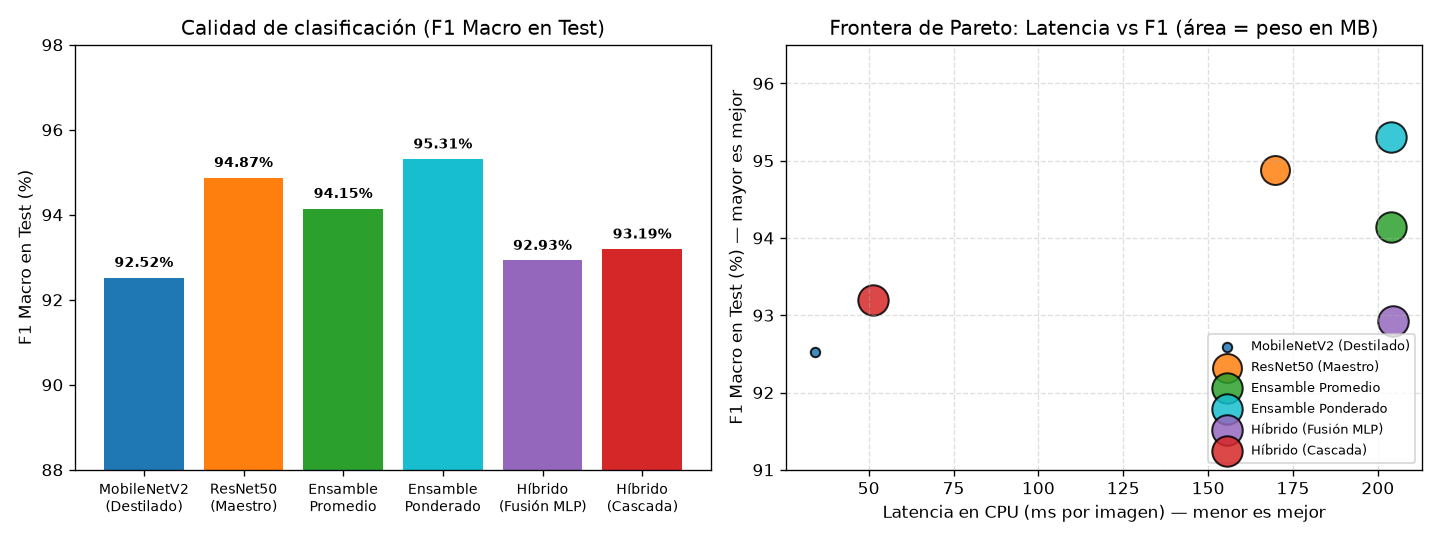

In [4]:
print(tabla_texto)
# Gráfica comparativa de F1 Macro vs Latencia y Peso en MB
plt.show()

## 4. Conclusión: ¿Qué modelo se queda en la aplicación como principal y por qué?

**Decisión:** El modelo que permanece como **modelo principal por defecto en la aplicación (`SemaforoIA`) es `MobileNetV2` (Estudiante Destilado)** (`10,0 MB`, `2,55 millones` de parámetros, `34,2 ms` por imagen en CPU), dejando a **`ResNet50` (Modelo Maestro)** como arquitectura de referencia seleccionable en la barra lateral.

**Justificación técnica y experimental:**
1. **Relación costo-beneficio y Frontera de Pareto:** Aunque el **Ensamble por Promedio**, el **Ensamble Ponderado**, el **Modelo Híbrido por Fusión MLP** y el **Maestro `ResNet50`** alcanzan el techo de exactitud en el conjunto de prueba (**95,14 % de Accuracy y 94,87 %–94,91 % de F1 macro**, con 12 errores sobre 247 imágenes), todos ellos exigen mantener en memoria los **24,56M–27,11M de parámetros (`94–105 MB` en FP32)** e incurren en una latencia de **`170 a 205 ms` por imagen en CPU** (6 veces más lentos que `MobileNetV2`).
2. **Compresión de 9,6× con retención del 97,5 % del F1:** Gracias al proceso de *Knowledge Distillation* ($T=4,0, \alpha=0,70$), `MobileNetV2` alcanza **92,71 % de Accuracy y 92,52 % de F1 macro** con todas las categorías por encima de `0,90` de F1, diferenciándose del Maestro y de los ensambles en **únicamente 6 fotografías de las 247 del conjunto de prueba** (`18` vs. `12` errores), pero reduciendo el peso en memoria en un **89,4 % (`10,0 MB` vs `94,0–104,8 MB`)** y acelerando la inferencia a **`34,2 ms` (~29 FPS en CPU)**.
3. **Restricciones de despliegue en la nube y en el borde (*Edge AI*):** En Streamlit Community Cloud (entorno compartido de CPU sin GPU y con límite estricto de RAM) y en controladores semafóricos de borde, ejecutar simultáneamente dos backbones convolucionales en cada inferencia (`204 ms` en los ensambles y en el híbrido de fusión) duplica el consumo de memoria y degrada la experiencia interactiva al calcular mapas Grad-CAM. Por ello, **`MobileNetV2` destilado** es la elección óptima de ingeniería para producción.